In [11]:
#2026.1.6
#小鼠1c-2c-4c拟时序 S-G1
import os

folder_path = '/home/lihaoxing/mouse_embryo_schic/oocyte_1c_2c_4c/150k_ice_matrix_S_G1'  # 替换为你想要遍历的文件夹的路径

for filenames in os.listdir(folder_path):
    filename = os.path.join(folder_path, filenames)
    filename_part1 = filename.split('/')
    filename_part2 = filename_part1[6].split('_')
    print(filename_part2[0])
    with open('/home/lihaoxing/resolution_bed_file/mm10_150k_range.bed', 'r') as f1:
        for line1 in f1.readlines():
            chr,min_bin,max_bin = line1.strip().split('\t')
            delta = int(int(min_bin)-1)
            # 处理每一行的内容，例如打印第一个字
            #print(chr,min_bin,max_bin)
            with open(filename, 'r') as f2:
                for line2 in f2.readlines():
                    bin1,bin2,counts = line2.strip().split('\t')
                    if int(min_bin) <=int(bin1) <=int(int(max_bin)-1) and int(min_bin) <=int(bin2) <=int(int(max_bin)-1):
                        #print(bin1+"\t"+bin2+"\t"+counts+"\n")
                        with open('/home/lihaoxing/try_scHiCluster/mouse_1c_2c_4c_cell_matrix/'+chr+"/"+filename_part2[0]+'_'+chr+'.txt', 'a') as f3:
                            f3.write(str(int(bin1)-int(delta))+"\t"+str(int(bin2)-int(delta))+"\t"+counts+"\n")

GSM3691084
GSM3691221
GSM3691031
GSM3691219
GSM3691133
GSM3691669
GSM3690990
GSM3691112
GSM3691049
GSM3691038
GSM3691052
GSM3691123
GSM3691095
GSM3691059
GSM3691074
GSM3691041
GSM3691274
GSM3691020
GSM3691264
GSM3691831
GSM3691254
GSM3691169
GSM3691113
GSM3691048
GSM3691103
GSM3691051
GSM3691030
GSM3691027
GSM3691223
GSM3691061
GSM3691213
GSM3691134
GSM3691202
GSM3691114
GSM3691118
GSM3691075
GSM3691050
GSM3691104
GSM3691026
GSM3691037
GSM3691234
GSM3691060
GSM3691286
GSM3690947
GSM3691058
GSM3691276
GSM3691145
GSM3691096
GSM3691203
GSM3690926
GSM3691115
GSM3691018
GSM3691105
GSM3691047
GSM3691012
GSM3690979
GSM3691124
GSM3691068
GSM3691128
GSM3691097
GSM3690937
GSM3691810
GSM3691011
GSM3691046
GSM3691106
GSM3691280
GSM3691186
GSM3691278
GSM3691126
GSM3690925
GSM3691019
GSM3691117
GSM3691257
GSM3691077
GSM3691035
GSM3691136
GSM3691056
GSM3691127
GSM3690931
GSM3690929
GSM3691107
GSM3691034
GSM3691045
GSM3691078
GSM3691070
GSM3691260
GSM3691137
GSM3691066
GSM3691821
GSM3691120
GSM3691092

In [ ]:
#hires_data
#随后在bash中运行如下命令
conda activate schicluster
res=150000
#head cell_list.txt 
#GSM3691084
#GSM3691221
#GSM3691031
#GSM3691219
#GSM3691133
#GSM3691669
#GSM3690990
#GSM3691112
#GSM3691049
#GSM3691038


#首先创建文件夹
for c in `seq 1 19`; do mkdir -p mouse_1c_2c_4c_cell_matrix/chr${c}/; done
for c in `seq 1 19`; do mkdir -p mouse_1c_2c_4c_imputed_matrix/chr${c}/; done
mkdir mouse_1c_2c_4c_imputed_matrix/filelist/
mkdir -p mouse_1c_2c_4c_imputed_matrix/merged/embed/

#下面的命令写在sh脚本里,用nohup运行，需要很长时间
cat cell_list.txt |while read line; do for c in `seq 1 19`; do command time hicluster impute-cell --indir mouse_1c_2c_4c_cell_matrix/chr${c}/ --outdir mouse_1c_2c_4c_imputed_matrix/chr${c}/ --cell $line --chrom ${c} --res 150000 --chrom_file /home/lihaoxing/HiC-Pro-3.1.0/annotation/chrom_mm10.sizes; done; done

#head cell_type.txt 
#GSM3691084	2c
#GSM3691221	4c
#GSM3691031	2c
#GSM3691219	4c
#GSM3691133	2c
#GSM3691669	oocyte
#GSM3690990	1c
#GSM3691112	2c
#GSM3691049	2c
#GSM3691038	2c

for c in `seq 1 19`; do awk -v c=$c '{printf("mouse_1c_2c_4c_imputed_matrix/chr%s/%s_chr%s_pad1_std1_rp0.5_sqrtvc.hdf5\n",c,$1,c)}' cell_type.txt > mouse_1c_2c_4c_imputed_matrix/filelist/imputelist_pad1_std1_rp0.5_sqrtvc_chr${c}.txt; echo $c; done


#下面的命令会报错`np.str` was a deprecated alias for the builtin `str`. To avoid this error in existing code, use `str` by itself. Doing this will not modify any behavior and is safe. If you specifically wanted the numpy scalar type, use `np.str_` here.
#需要将/home/lihaoxing/miniconda3/lib/python3.9/site-packages/schicluster/draft/embed_concatcell_chr.py中的np.str修改为str
for c in `seq 1 19`; do command time hicluster embed-concatcell-chr --cell_list mouse_1c_2c_4c_imputed_matrix/filelist/imputelist_pad1_std1_rp0.5_sqrtvc_chr${c}.txt --outprefix mouse_1c_2c_4c_imputed_matrix/merged/embed/pad1_std1_rp0.5_sqrtvc_chr${c} --res 150000; done

ls mouse_1c_2c_4c_imputed_matrix/merged/embed/*npy > mouse_1c_2c_4c_imputed_matrix/filelist/embedlist_pad1_std1_rp0.5_sqrtvc.txt

#需要将/home/lihaoxing/miniconda3/lib/python3.9/site-packages/schicluster/draft/embed_mergechr.py 中的np.str修改为str
command time hicluster embed-mergechr --embed_list mouse_1c_2c_4c_imputed_matrix/filelist/embedlist_pad1_std1_rp0.5_sqrtvc.txt --outprefix mouse_1c_2c_4c_imputed_matrix/merged/embed/pad1_std1_rp0.5_sqrtvc

2026-03-03 11:07:12.210631: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-03-03 11:07:26.199972: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT


6


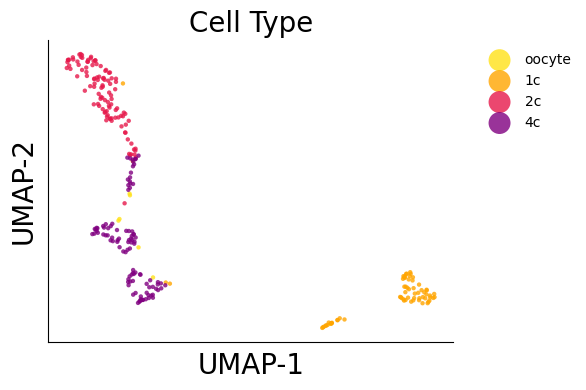

In [1]:
#mouse_1c_2c_4c_imputed_matrix
#G1 S 期
#150k
import h5py
import numpy as np
import pandas as pd
from scipy.stats import ks_2samp
from sklearn.cluster import KMeans  # 导入KMeans
from umap import UMAP
import matplotlib as mpl
import matplotlib.pyplot as plt
from IPython.display import SVG, display

#mpl.style.use('default')
#mpl.rcParams['pdf.fonttype'] = 42
#mpl.rcParams['ps.fonttype'] = 42

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

# 自定义颜色
color_map = {
    "oocyte": "#ffe119",  # 黄色
    "1c":     "orange",   # 绿色
    "2c":     "#e6194b",   # 红色
    "4c":     "purple"  
}

# 加载嵌入数据
with h5py.File('/home/lihaoxing/try_scHiCluster/mouse_1c_2c_4c_imputed_matrix/merged/embed/pad1_std1_rp0.5_sqrtvc.svd20.hdf5', 'r') as f:
    matrix_reduce = f['data'][()]

# 确定使用的维度数量
for ndim in range(100):
    p = ks_2samp(matrix_reduce[:, ndim], matrix_reduce[:, ndim + 1]).pvalue
    if p > 0.01:
        break

ndim += 1
print(ndim)
ndim = 8  # 手动设置维度数量
umap = UMAP(n_neighbors=20, random_state=0)
y = umap.fit_transform(matrix_reduce[:, :ndim])

# 加载标签数据
label = pd.read_csv('/home/lihaoxing/try_scHiCluster/cell_type.txt', sep='\t', header=None, index_col=0)
label['batch'] = ['_'.join(x.split('_')[:2]) for x in label.index]

# 进行聚类
kmeans = KMeans(n_clusters=3, random_state=0).fit(matrix_reduce[:, :ndim])
label['cluster'] = kmeans.labels_ + 1

# 保存UMAP坐标和标签到TXT文件（制表符分隔）
umap_df = pd.DataFrame(y, columns=['UMAP-1', 'UMAP-2'])
umap_df['Cell_ID'] = label['batch'].values
umap_df['Cell_Type'] = label[1].values
umap_df['Cluster'] = label['cluster'].values
umap_df.to_csv('mouse_1c_2c_4c_150k_8dim_20nei_umap_embeddings.txt', 
               sep='\t',  # 使用制表符作为分隔符
               index=True)  # 保留索引列

# 绘图
ds = 10
fig, ax = plt.subplots(figsize=(6, 4))
ax.set_xlabel('UMAP-1', fontsize=20)
ax.set_ylabel('UMAP-2', fontsize=20)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.tick_params(axis='both', which='both', length=0)
ax.set_xticklabels([])
ax.set_yticklabels([])
ax.set_title('Cell Type', fontsize=20)

# 绘制散点图
for cell_type, color in color_map.items():
    cell = (label[1] == cell_type)
    ax.scatter(
        y[cell, 0],
        y[cell, 1],
        c=color,
        s=ds,
        edgecolors='none',
        alpha=0.8,
        label=f"{cell_type}",  # 修改图例标注
        rasterized=True
    )

# 调整图例
ax.legend(
    markerscale=5,
    prop={'size': 10},
    bbox_to_anchor=(1.05, 1),
    loc='upper left',
    fontsize=15,
    frameon=False
)

# 自动调整布局
plt.tight_layout()

# 保存图像
plt.savefig('mouse_1c_2c_4c_150k.svg', dpi=300, bbox_inches='tight', transparent=True)



In [2]:
#Step 1: 准备输入数据
from py_monocle import learn_graph, order_cells, compute_cell_states

# 假设 y 是 UMAP 降维后的坐标，label['cluster'] 是聚类标签
umap = y
louvain = label['cluster'].values  # 或者你也可以换成其他聚类结果


In [3]:
import scanpy as sc
import anndata as ad
import numpy as np
from py_monocle import learn_graph

# Assuming `umap` is your N x 2 array from UMAP
adata = ad.AnnData(np.zeros((umap.shape[0], 0)))  # dummy expression
adata.obsm['X_umap'] = umap

# Step 1: build nearest neighbor graph
sc.pp.neighbors(adata, use_rep='X_umap', n_neighbors=15)

# Step 2: run Leiden clustering
sc.tl.leiden(adata, resolution=0.1)  # try different resolutions if needed
leiden_clusters = adata.obs['leiden'].astype(int).values  # convert to integers

/home/lihaoxing/tmp/ipykernel_851783/871411249.py:14: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(adata, resolution=0.1)  # try different resolutions if needed


In [4]:
#Step 2: 构建主图结构（principal graph）
projected_points, mst, centroids = learn_graph(matrix=umap, clusters=leiden_clusters)

#Step 3: 拟时序推断
# 这里 root_cells 设置为 0，也可以自己手动指定起始细胞索引
pseudotime = order_cells(
    umap,
    centroids,
    mst=mst,
    projected_points=projected_points,
    root_cells=0,
)


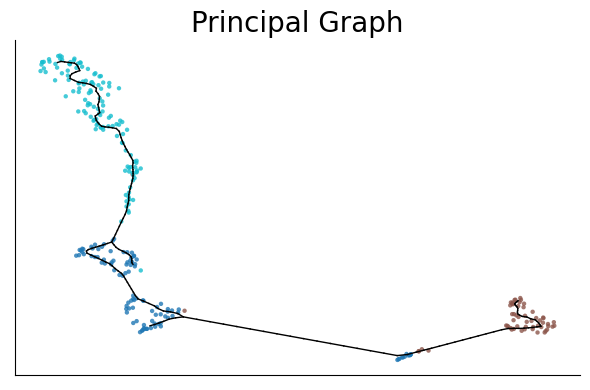

In [6]:
# Step 1: Principal Graph
fig, ax = plt.subplots(figsize=(6, 4))
ax.set_title("Principal Graph", fontsize=20)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.set_xticks([])
ax.set_yticks([])

# 画细胞点
scatter = ax.scatter(
    umap[:, 0],
    umap[:, 1],
    c=louvain,
    s=10,
    cmap="tab10",
    edgecolors='none',
    alpha=0.8,
    rasterized=True
)

# ===== 从 mst 提取 edges =====
import numpy as np

# 如果 mst 是稀疏矩阵
if hasattr(mst, "toarray"):
    mst_array = mst.toarray()
else:
    mst_array = mst

edges = np.transpose(np.nonzero(np.triu(mst_array)))

# 画 graph 边
for i, j in edges:
    ax.plot(
        [centroids[i, 0], centroids[j, 0]],
        [centroids[i, 1], centroids[j, 1]],
        c="black",
        linewidth=1
    )

plt.tight_layout()
plt.savefig("mouse_Principal_Graph.svg", dpi=300, bbox_inches='tight', transparent=True)
plt.show()

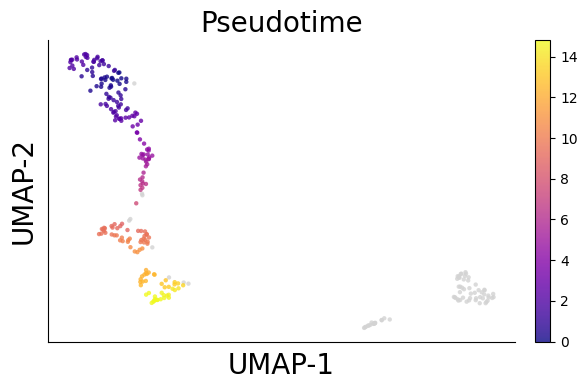

In [13]:
# label[1] 是 cell type
exclude_mask = label[1].isin(["oocyte", "1c"]).values
include_mask = ~exclude_mask

fig, ax = plt.subplots(figsize=(6, 4))
ax.set_title("Pseudotime", fontsize=20)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel('UMAP-1', fontsize=20)
ax.set_ylabel('UMAP-2', fontsize=20)

# 1️⃣ 先画灰色背景细胞（oocyte + 1c）
ax.scatter(
    umap[exclude_mask, 0],
    umap[exclude_mask, 1],
    c="lightgray",
    s=10,
    edgecolors='none',
    alpha=0.8,
    rasterized=True
)

# 2️⃣ 再画参与拟时序的细胞
sc = ax.scatter(
    umap[include_mask, 0],
    umap[include_mask, 1],
    c=pseudotime[include_mask],
    s=10,
    cmap="plasma",
    edgecolors='none',
    alpha=0.8,
    rasterized=True
)

# colorbar 只对应参与时序的细胞
cbar = plt.colorbar(sc, ax=ax, fraction=0.046, pad=0.04)
cbar.ax.tick_params(labelsize=10)

plt.tight_layout()
plt.savefig('mouse_Pseudotime_filtered.svg',
            dpi=300, bbox_inches='tight', transparent=True)
plt.show()